## Week 5 Project — Task Sheet

## Linear Model Pipeline

## Part 1 — Baseline before beauty

## TASK 01 — Load, explore, and define the target

In [ ]:
# Task 01: Load, Explore, and Define the Target

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("california_housing.csv")

# 2. Print dataset shape
print("Dataset Shape:", df.shape)

# 3. Display the first five rows
print("\nFirst Five Rows:")
print(df.head())

# 4. Inspect column data types
print("\nColumn Data Types:")
print(df.dtypes)

# 5. Check missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# 6. Define features and target
target_column = "MedHouseVal"

X = df.drop(columns=[target_column])
y = df[target_column]

# 7. Define the target in one clear sentence
print("\nTarget Definition:")
print(
    "We are predicting the median house value for a California "
    "census block group; higher values indicate higher median "
    "house values, measured in units of $100,000."
)

# 8. Handle missing values
print("\nMissing Values in Target:", y.isnull().sum())

if X.isnull().sum().sum() == 0 and y.isnull().sum() == 0:
    print("No missing values found. No missing-value treatment is needed.")
else:
    print("Missing values found. They will be handled during preprocessing.")
    print("Numerical features: median imputation.")
    print("Missing target values: remove those rows before training.")

# 9. Plot the target distribution
plt.figure(figsize=(8, 5))
plt.hist(y.dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (units of $100,000)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


**1. Feature Meanings:**
- **MedInc:** Median household income.
- **HouseAge:** Median house age.
- **AveRooms:** Average rooms per household.
- **AveBedrms:** Average bedrooms per household.
- **Population:** Total population.
- **AveOccup:** Average people per household.
- **Latitude:** North–south location.
- **Longitude:** East–west location.
- **MedHouseVal:** Median house value (target).

**2. Why check target distribution?**  
To understand the range, spread, skewness, and unusual values in house prices.

**3. Dataset Summary:**  
The California Housing dataset contains housing and demographic information, and our model predicts median house values.

## TASK 02 — Make the train/test split once, and freeze the test set

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the dataset
df = pd.read_csv("california_housing.csv")

# Separate features and target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Check the shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (4000, 8)
Testing features: (1000, 8)
Training target: (4000,)
Testing target: (1000,)


### Purpose of Each Dataset

- **Training set:** Used to train the model.
- **Validation/Cross-validation:** Used to compare models and tune hyperparameters.
- **Test set:** Used only once for the final evaluation.

**Result:** 80% of the data is used for training and 20% is reserved for final testing.

**1. Why split before scaling?**  
To prevent data leakage and ensure the test set remains unseen during preprocessing.

**2. What is data leakage?**  
Data leakage occurs when information from the test set influences model training or preprocessing, leading to overly optimistic evaluation results.

## TASK 03 — Build a dumb baseline first

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

# Create a baseline model that always predicts the mean house value
baseline = DummyRegressor(strategy="mean")

# Evaluate using 5-fold cross-validation on training data only
scores = cross_val_score(
    baseline, X_train, y_train, cv=5, scoring="r2"
)

# Display the average R² score
print("Baseline CV R²:", round(scores.mean(), 3))


Baseline CV R²: -0.002


**1. Why is the baseline useful?**  
It provides a minimum performance benchmark to check whether our actual model learns useful patterns.

**2. What does `cross_val_score` do?**  
It evaluates a model across multiple data splits and averages the scores, giving a more reliable performance estimate than a single split.

## TASK 04 — One plain model, and feel the problem

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

# Create a plain Linear Regression model
lr = LinearRegression()

# Train the model
lr.fit(X_train, y_train)

# Evaluate using 5-fold cross-validation
scores = cross_val_score(
    LinearRegression(), X_train, y_train, cv=5, scoring="r2"
)

print("Plain LR CV R²:", round(scores.mean(), 3))

# Check coefficient magnitudes
print(
    "Coefficient range:",
    round(lr.coef_.min(), 2),
    "to",
    round(lr.coef_.max(), 2)
)


Plain LR CV R²: 0.84
Coefficient range: -0.14 to 0.4


Interpretation:
- Compare the CV R² score with your dummy baseline.
- Large coefficient magnitudes may reflect different feature scales, but large coefficients alone do not prove a problem.
- In the next step, you will use standardisation to put features on comparable scales.

**1. Why are linear models sensitive to feature scales?**  
Linear models depend on coefficient values, so different feature scales can affect training and regularisation. Tree models split features by thresholds, so scaling is generally unnecessary.

**2. Is the plain model beating the baseline?**  
Compare their cross-validation R² scores. If the linear model's score is higher, it beats the baseline by learning useful patterns from the features.

## Part 2 — Regularised variants, tune, interpret, deliver

## TASK 05 — Add Ridge and Lasso, your next variants


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

# Define all models
baseline = DummyRegressor(strategy="mean")
lr = LinearRegression()
scaled_ridge = make_pipeline(StandardScaler(), Ridge())
scaled_lasso = make_pipeline(StandardScaler(), Lasso())

# Compare models using 5-fold cross-validation
models = {
    "Baseline": baseline,
    "Plain Linear Regression": lr,
    "Ridge": scaled_ridge,
    "Lasso": scaled_lasso
}

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="r2"
    )
    print(f"{name} CV R²: {scores.mean():.3f}")

# Fit Ridge and Lasso to compare coefficients
scaled_ridge.fit(X_train, y_train)
scaled_lasso.fit(X_train, y_train)

ridge_coef = scaled_ridge.named_steps["ridge"].coef_
lasso_coef = scaled_lasso.named_steps["lasso"].coef_

print("\nRidge coefficients:", np.round(ridge_coef, 4))
print("Lasso coefficients:", np.round(lasso_coef, 4))

print("Ridge exact zeros:", np.sum(ridge_coef == 0))
print("Lasso exact zeros:", np.sum(lasso_coef == 0))


Baseline CV R²: -0.002
Plain Linear Regression CV R²: 0.840
Ridge CV R²: 0.840
Lasso CV R²: -0.002

Ridge coefficients: [ 0.8797  0.1696  0.034   0.0019 -0.0022 -0.1121 -0.1491 -0.17  ]
Lasso coefficients: [0. 0. 0. 0. 0. 0. 0. 0.]
Ridge exact zeros: 0
Lasso exact zeros: 8


**1. Why scale features before Ridge/Lasso?**
Ridge and Lasso penalise coefficient sizes, so scaling ensures features are penalised fairly. Ordinary Linear Regression does not require scaling.

**2. What does alpha control?**
Alpha controls the strength of regularisation: higher alpha means stronger penalties and simpler models, while lower alpha means weaker penalties and more flexibility.

## TASK 06 — Tune your best regularised variant with cross-validation

In [8]:
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import numpy as np

# Create a pipeline and tune alpha using cross-validation
lasso_cv = make_pipeline(
    StandardScaler(),
    LassoCV(
        alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10],
        cv=5,
        max_iter=20000
    )
)

# Fit using training data only
lasso_cv.fit(X_train, y_train)

# Display the best alpha
best_alpha = lasso_cv.named_steps["lassocv"].alpha_
print("Best alpha:", best_alpha)

# Evaluate using cross-validation on training data
scores = cross_val_score(
    lasso_cv, X_train, y_train, cv=5, scoring="r2"
)
print("CV R²:", round(scores.mean(), 3))

# Count coefficients that became zero
lasso_model = lasso_cv.named_steps["lassocv"]
zero_count = np.sum(lasso_model.coef_ == 0)

print("Number of zero coefficients:", zero_count)
print("Total features:", len(lasso_model.coef_))


Best alpha: 0.001
CV R²: 0.84
Number of zero coefficients: 0
Total features: 8


Note: The test set remains untouched. LassoCV selects the best alpha using cross-validation within the training data. The final coefficient count shows how many features Lasso excluded by assigning them zero coefficients.

1\. Why is cross-validation better?\
It evaluates the model on multiple data splits, giving a more reliable estimate of performance on unseen data.

2\. How does alpha affect coefficients?\
Larger alpha shrinks coefficients more and may set some to zero; smaller alpha applies weaker penalties, allowing larger coefficients.

Q: Why must alpha be chosen with CV, never by peeking at the test set?

Answer: Alpha must be chosen using cross-validation to prevent data leakage and keep the test set unbiased for final evaluation.

## TASK 07 — Wrap it in one clean sklearn Pipeline

In [9]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import cross_val_score

# Create the complete pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LassoCV(
        alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10],
        cv=5,
        max_iter=20000
    ))
])

# Evaluate using cross-validation on training data
scores = cross_val_score(
    pipeline, X_train, y_train, cv=5, scoring="r2"
)

print("Pipeline CV R²:", round(scores.mean(), 3))

# Fit the final pipeline on all training data
pipeline.fit(X_train, y_train)

print("Best alpha:", pipeline.named_steps["model"].alpha_)


Pipeline CV R²: 0.84
Best alpha: 0.001


Meaning: The pipeline scales features and trains Lasso regression together, helping prevent preprocessing leakage during cross-validation. The test set remains untouched

Q1. Why does putting the scaler inside the Pipeline stop leakage, even on the final test evaluation?\
Answer: The scaler learns statistics only from training data and applies them to test data without learning from it.

Q2. What is the difference between fitting the Pipeline on `X_train` and refitting it inside `cross_val_score`?\
Answer: `pipeline.fit(X_train, y_train)` trains on all training data, while `cross_val_score` creates separate models for each fold, fitting preprocessing only on each fold's training portion.

## TASK 08 — Interpret the model, do not just report a number

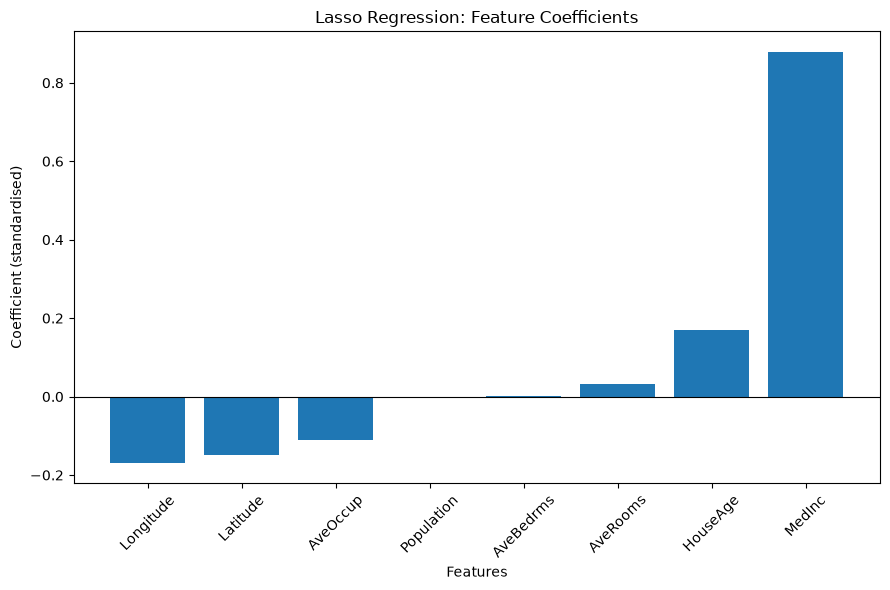

      Feature  Coefficient
7   Longitude    -0.169046
6    Latitude    -0.148132
5    AveOccup    -0.111126
4  Population    -0.001221
3   AveBedrms     0.000923
2    AveRooms     0.032974
1    HouseAge     0.168567
0      MedInc     0.878838
Number of zero coefficients: 0


In [12]:

import matplotlib.pyplot as plt
import pandas as pd

# Extract feature names and trained Lasso coefficients
coefs = pipeline.named_steps["model"].coef_

# Create a coefficient table
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefs
}).sort_values("Coefficient")

# Plot coefficients
plt.figure(figsize=(9, 6))
plt.bar(coef_df["Feature"], coef_df["Coefficient"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Lasso Regression: Feature Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient (standardised)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(coef_df)
print("Number of zero coefficients:", (coefs == 0).sum())


1\. Why standardised coefficients?\
Standardisation puts features on the same scale, making their coefficient magnitudes easier to compare fairly.

2\. Which features were most meaningful or irrelevant?\
Features with the largest absolute coefficients had the strongest influence on predictions. Features with zero coefficients were removed by Lasso. The exact features depend on my model's output.

3\. How does the chart help my manager?\
It shows which housing features increase or decrease predicted house values and which features Lasso considers less useful.

## TASK 09 — The final score, the comparison table, and the deliverable

FINAL test score: 0.838

MODEL COMPARISON TABLE
            Model  Mean CV R²  CV Std  Final Test R²
         Baseline      -0.002   0.002            NaN
Linear Regression       0.840   0.011            NaN
            Ridge       0.840   0.011            NaN
            Lasso       0.840   0.011          0.838

LASSO COEFFICIENTS
   Feature  Coefficient
 Longitude    -0.169046
  Latitude    -0.148132
  AveOccup    -0.111126
Population    -0.001221
 AveBedrms     0.000923
  AveRooms     0.032974
  HouseAge     0.168567
    MedInc     0.878838

Number of zero coefficients: 0


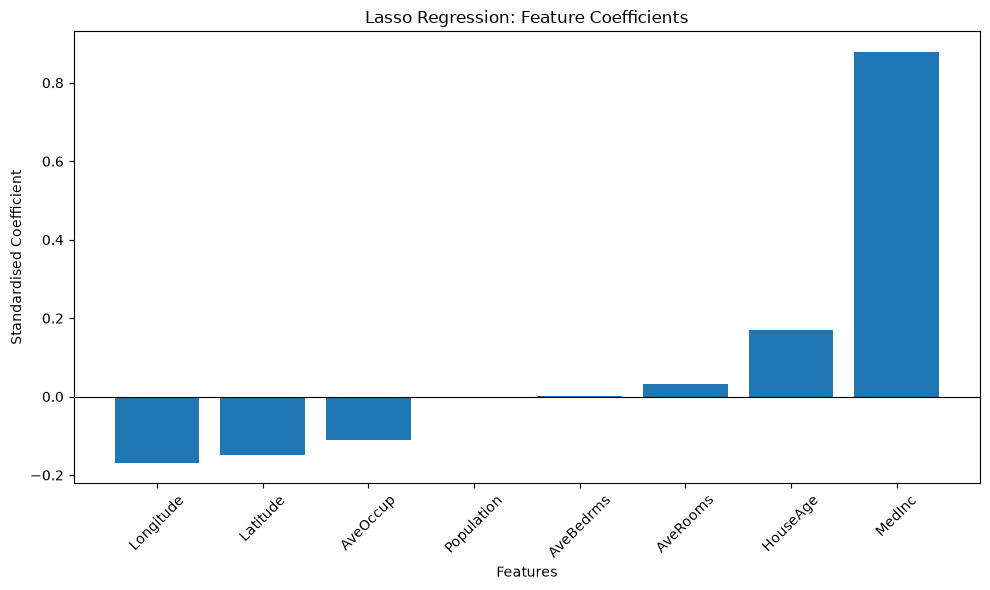

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, LassoCV

# 1. Load the dataset
df = pd.read_csv("california_housing.csv")

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# 2. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Define the models
baseline = DummyRegressor(strategy="mean")
plain = LinearRegression()
ridge = make_pipeline(StandardScaler(), Ridge())

lasso = make_pipeline(
    StandardScaler(),
    LassoCV(
        alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10],
        cv=5,
        max_iter=20000
    )
)

models = {
    "Baseline": baseline,
    "Linear Regression": plain,
    "Ridge": ridge,
    "Lasso": lasso
}

# 4. Calculate cross-validation scores on training data
results = []

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="r2"
    )
    results.append({
        "Model": name,
        "Mean CV R²": round(scores.mean(), 3),
        "CV Std": round(scores.std(), 3),
        "Final Test R²": None
    })

# 5. Fit the selected Lasso Pipeline on training data
lasso.fit(X_train, y_train)

# 6. Evaluate the test set exactly once
final_test_score = lasso.score(X_test, y_test)
print("FINAL test score:", round(final_test_score, 3))

for result in results:
    if result["Model"] == "Lasso":
        result["Final Test R²"] = round(final_test_score, 3)

# 7. Create and save the comparison table
comparison_df = pd.DataFrame(results)
print("\nMODEL COMPARISON TABLE")
print(comparison_df.to_string(index=False))

comparison_df.to_csv("model_comparison.csv", index=False)

# 8. Interpret Lasso coefficients
coefficients = lasso.named_steps["lassocv"].coef_

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients
}).sort_values("Coefficient")

print("\nLASSO COEFFICIENTS")
print(coef_df.to_string(index=False))
print("\nNumber of zero coefficients:", (coefficients == 0).sum())

# 9. Plot and save the coefficient chart
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(coef_df["Feature"], coef_df["Coefficient"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Lasso Regression: Feature Coefficients")
ax.set_xlabel("Features")
ax.set_ylabel("Standardised Coefficient")
plt.xticks(rotation=45)
fig.tight_layout()
fig.savefig("coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

1\. Test score vs. CV score:\
I compare the final test R² with the Lasso mean CV R². If the test score is lower, CV overestimated performance; if they are close, the model generalises consistently.

2\. Ridge vs. Lasso:\
I would recommend Ridge if all housing features contribute useful information, especially when features are correlated. I would recommend Lasso if simpler models and automatic feature selection are important.

3\. Best chart and interpretation:\
The Lasso coefficient bar chart best explains which features are positively or negatively associated with predicted house values and which features have zero coefficients. The comparison table supports this by showing model performance.